In [5]:
import numpy as np
import pandas as pd

In [ ]:
'''
stage_1_rank1:
graph_path_1 = './result/w_layer/stage1/tuning/bs32_dp0.8_sw0.7/dynamic_full_graphs.npy'
label_path_1 = './result/w_layer/stage1/df_scaled.csv'

graph_path_2 = './result/wo_layer/stage1/tuning/bs8_dp0.1_sw1.0/dynamic_full_graphs.npy'
label_path_2 = './result/wo_layer/stage1/df_scaled.csv'
##################
stage_2_rank1:
graph_path_1 = './result/w_layer/stage2/tuning/bs32_dp0.8_sw0.7/dynamic_full_graphs.npy'
label_path_1 = './result/w_layer/stage2/df_scaled.csv'

graph_path_2 = './result/wo_layer/stage2/tuning/bs64_dp0.8_sw1.0/dynamic_full_graphs.npy'
label_path_2 = './result/wo_layer/stage2/df_scaled.csv'
#################
stage_3_rank1:
graph_path_1 = './result/w_layer/stage3/tuning/bs64_dp0.3_sw0.7/dynamic_full_graphs.npy'
label_path_1 = './result/w_layer/stage3/df_scaled.csv'

graph_path_2 = './result/wo_layer/stage3/tuning/bs32_dp0.8_sw1.0/dynamic_full_graphs.npy'
label_path_2 = './result/wo_layer/stage3/df_scaled.csv'


'''

## stage1

In [12]:
import numpy as np
import pandas as pd
import brainglobe_heatmap as bgh
import matplotlib.pyplot as plt

graph_path_1 = './result/w_layer/stage1/tuning/bs32_dp0.8_sw0.7/dynamic_full_graphs.npy'
label_path_1 = './result/w_layer/stage1/df_scaled.csv'

graph_path_2 = './result/wo_layer/stage1/tuning/bs8_dp0.1_sw1.0/dynamic_full_graphs.npy'
label_path_2 = './result/wo_layer/stage1/df_scaled.csv'

def compute_mean_degree_centrality(graph_path, label_path):
    graphs = np.load(graph_path)  
    df = pd.read_csv(label_path)
    labels = df.iloc[:, 0].values  

    degree_centrality = {label: [] for label in labels}

    for t in range(graphs.shape[0]):
        adj = graphs[t]
        degrees = np.sum(adj, axis=1)
        norm_degrees = degrees / (adj.shape[0] - 1)
        for i, region in enumerate(labels):
            degree_centrality[region].append(norm_degrees[i])

    dc_df = pd.DataFrame(degree_centrality)
    mean_dc = dc_df.mean()

    merged = {}
    for name, val in mean_dc.items():
        if '-' in name:
            key = name #.split('-')[0]
            merged.setdefault(key, []).append(val)
        else:
            merged.setdefault(name, []).append(val)
    merged_dc = pd.Series({k: pd.Series(v).mean() for k, v in merged.items()})
    return merged_dc


mean_dc_1 = compute_mean_degree_centrality(graph_path_1, label_path_1)
mean_dc_2 = compute_mean_degree_centrality(graph_path_2, label_path_2)

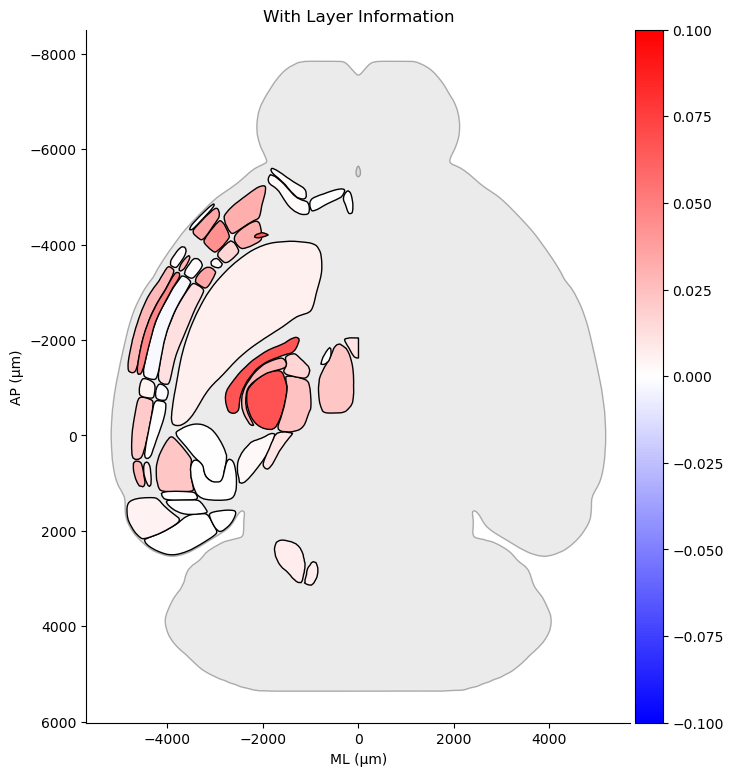

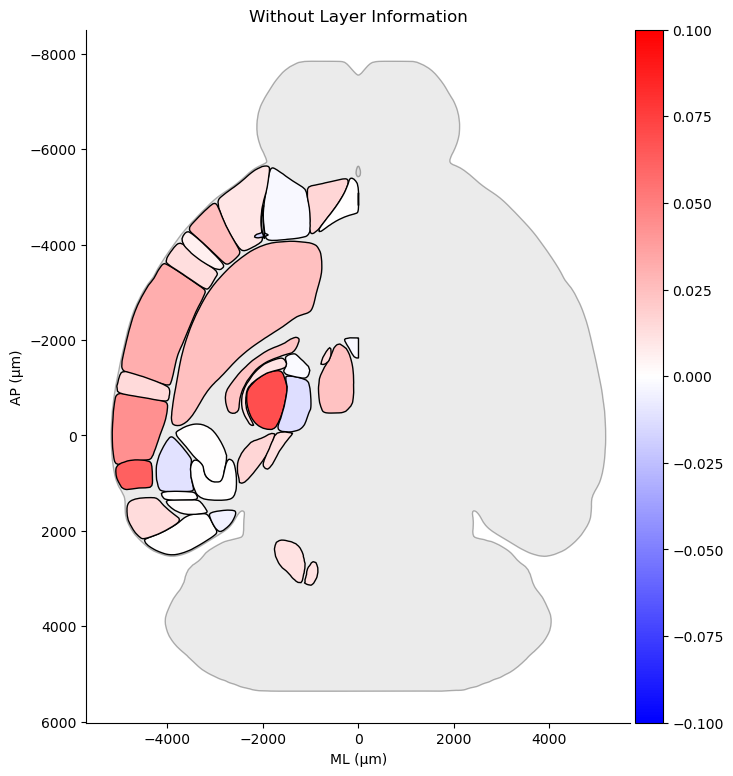

In [10]:
import numpy as np
import pandas as pd
import brainglobe_heatmap as bgh

values1 = mean_dc_1.to_dict()
values2 = mean_dc_2.to_dict()

vmin = -0.1
vmax = 0.1

fig = bgh.Heatmap(
    values=values1,
    hemisphere="left",
    position=4000,
    orientation="horizontal",
    thickness=1500,
    vmin=vmin,
    vmax=vmax,
    cmap="bwr",
    format="2D",
    atlas_name="allen_mouse_25um",
    title="With Layer Information"
).show(xlabel='ML (μm)', ylabel='AP (μm)')

fig = bgh.Heatmap(
    values=values2,
    hemisphere="left",
    position=4000,
    orientation="horizontal",
    thickness=1500,
    vmin=vmin,
    vmax=vmax,
    cmap="bwr",
    format="2D",
    atlas_name="allen_mouse_25um",
    title="Without Layer Information"
).show(xlabel='ML (μm)', ylabel='AP (μm)')

r = 0.271, p = 1.365e-02, MAE = 0.0118


/tmp/ipykernel_270174/194607632.py:53: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(fontsize=25)


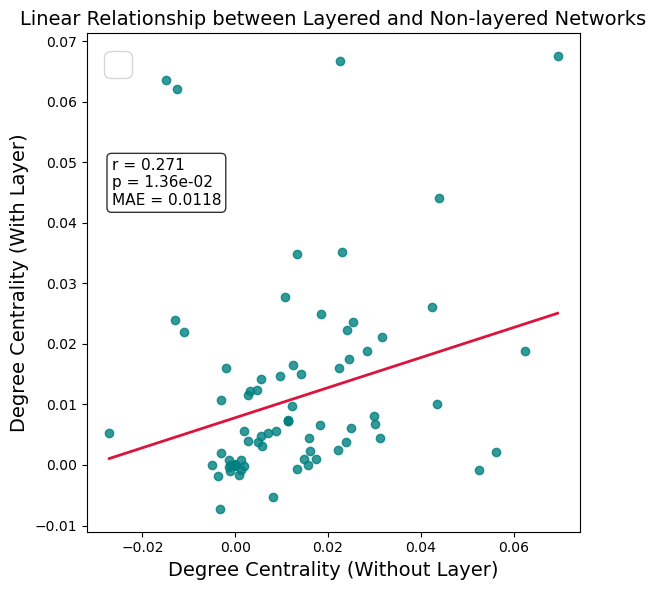

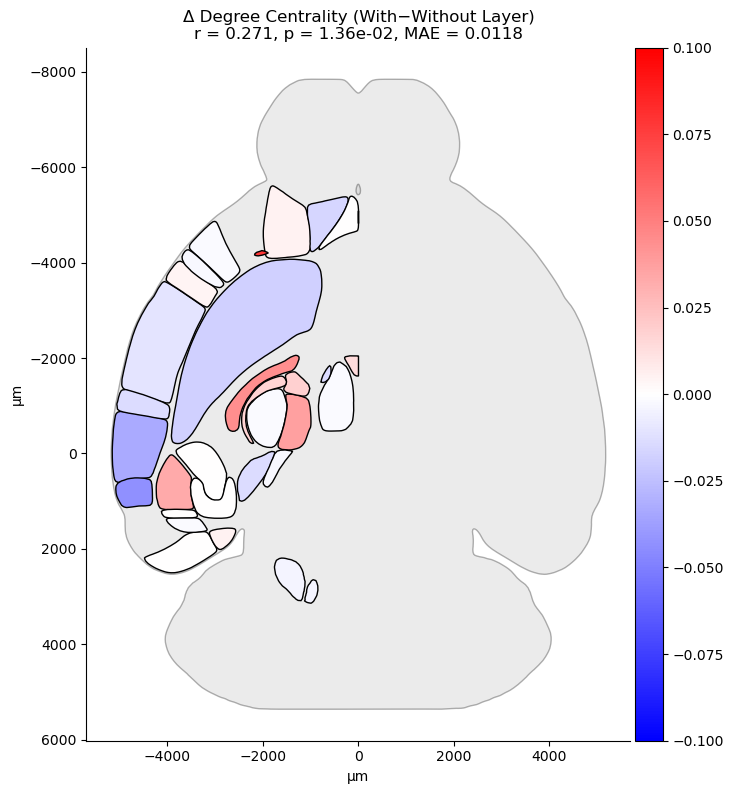

In [13]:
import re
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import pearsonr
import brainglobe_heatmap as bgh
from scipy.stats import linregress

w_layer = mean_dc_1.copy()
wo_layer = mean_dc_2.copy()


def get_base_region(name):
    df = pd.read_csv("./data/region_map.csv", sep="\t")
    region_dict = dict(zip(df.iloc[:,0], df.iloc[:,1]))
    return region_dict.get(name, name)

grouped = {}
for region, val in w_layer.items():
    base = get_base_region(region)
    grouped.setdefault(base, []).append(val)

layer_mean = {base: np.nanmean(vals) for base, vals in grouped.items()}
layer_mean = pd.Series(layer_mean)

common_regions = sorted(set(layer_mean.index) & set(wo_layer.index))
aligned_w = layer_mean[common_regions]
aligned_wo = wo_layer[common_regions]


r, p = pearsonr(aligned_w, aligned_wo)
mae = np.mean(np.abs(aligned_w - aligned_wo))
print(f"r = {r:.3f}, p = {p:.3e}, MAE = {mae:.4f}")

plt.figure(figsize=(6,6))
plt.scatter(aligned_wo, aligned_w, color="teal", alpha=0.8, label="")

slope, intercept, r_val, p_val, stderr = linregress(aligned_wo, aligned_w)

x_fit = np.linspace(aligned_wo.min(), aligned_wo.max(), 100)
y_fit = slope * x_fit + intercept
plt.plot(x_fit, y_fit, color="crimson", linewidth=2, label="")

plt.xlabel("Degree Centrality (Without Layer)", fontsize=14)
plt.ylabel("Degree Centrality (With Layer)", fontsize=14)
plt.title("Linear Relationship between Layered and Non-layered Networks", fontsize=14)

text_str = f"r = {r:.3f}\np = {p:.2e}\nMAE = {mae:.4f}"
plt.text(0.05, 0.75, text_str, transform=plt.gca().transAxes,
         fontsize=11, verticalalignment='top',
         bbox=dict(boxstyle="round", facecolor="white", alpha=0.8))

plt.legend(fontsize=25)
plt.grid(alpha=0)
plt.tight_layout()
plt.savefig("./result/fig/scatter_with_vs_without_layer_stage1.png", dpi=300, bbox_inches="tight")

plt.show()



diff_map = (aligned_w - aligned_wo).to_dict()

fig = bgh.Heatmap(
    values=diff_map,
    hemisphere="left",
    position=4000,
    orientation="horizontal",
    thickness=1500,
    format="2D",
    vmin=-0.1,
    vmax=0.1,
    cmap="bwr",
    atlas_name="allen_mouse_25um",
    title=f"Δ Degree Centrality (With−Without Layer)\n"
          f"r = {r:.3f}, p = {p:.2e}, MAE = {mae:.4f}"
).plot(size=(400,300), axes=False)

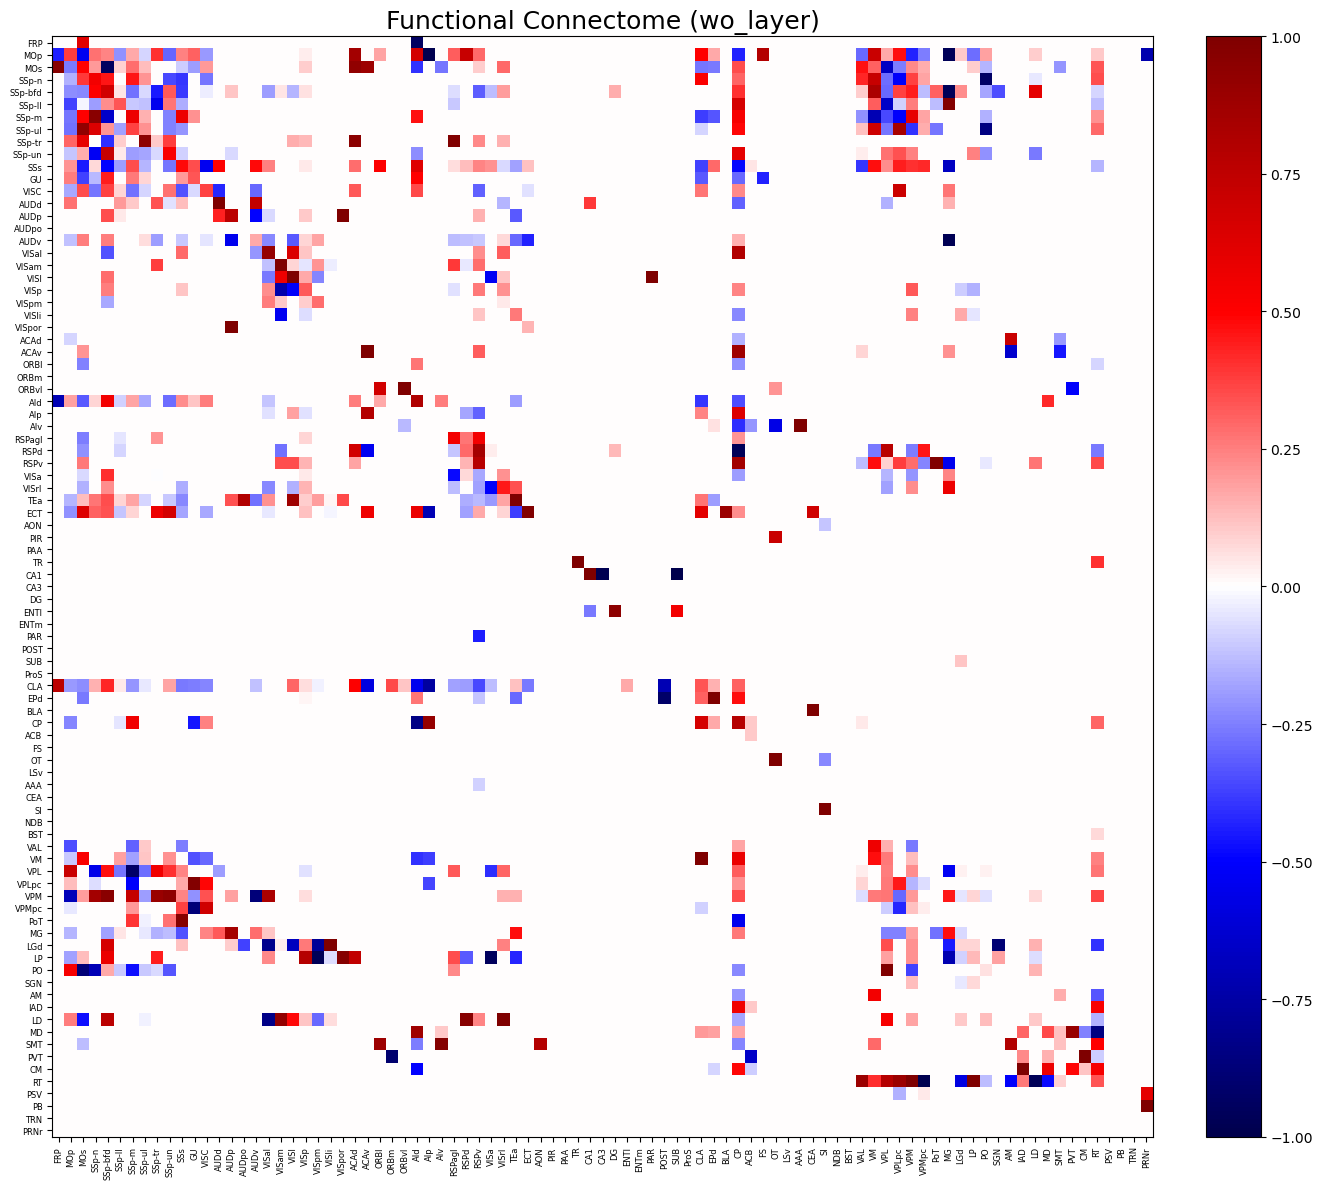

In [12]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import rcParams

rcParams['pdf.fonttype'] = 42
rcParams['ps.fonttype'] = 42

graphs = np.load(graph_path_2)
df = pd.read_csv(label_path_2)
labels = df.iloc[:, 0].astype(str).str.strip().values

adj_matrix = graphs.mean(axis=0)

plt.figure(figsize=(14, 12))

im = plt.imshow(adj_matrix, cmap="seismic", aspect="equal", vmin=-1, vmax=1)

plt.title("Functional Connectome (wo_layer)", fontsize=18)

plt.xticks(ticks=np.arange(len(labels)), labels=labels, rotation=90, fontsize=6)
plt.yticks(ticks=np.arange(len(labels)), labels=labels, fontsize=6)

cbar = plt.colorbar(im, fraction=0.046, pad=0.04)
cbar.ax.tick_params(labelsize=10)

plt.tight_layout()

plt.savefig("./result/fig/functional_connectome_wo_layer_stage1.jpg", format="jpg", dpi=300)
plt.show()


## stage2

In [8]:
import numpy as np
import pandas as pd
import brainglobe_heatmap as bgh
import matplotlib.pyplot as plt

graph_path_1 = './result/w_layer/stage2/tuning/bs32_dp0.8_sw0.7/dynamic_full_graphs.npy'
label_path_1 = './result/w_layer/stage2/df_scaled.csv'

graph_path_2 = './result/wo_layer/stage2/tuning/bs64_dp0.8_sw1.0/dynamic_full_graphs.npy'
label_path_2 = './result/wo_layer/stage2/df_scaled.csv'

def compute_mean_degree_centrality(graph_path, label_path):
    graphs = np.load(graph_path)  
    df = pd.read_csv(label_path)
    labels = df.iloc[:, 0].values  

    degree_centrality = {label: [] for label in labels}

    for t in range(graphs.shape[0]):
        adj = graphs[t]
        degrees = np.sum(adj, axis=1)
        norm_degrees = degrees / (adj.shape[0] - 1)
        for i, region in enumerate(labels):
            degree_centrality[region].append(norm_degrees[i])

    dc_df = pd.DataFrame(degree_centrality)
    mean_dc = dc_df.mean()

    merged = {}
    for name, val in mean_dc.items():
        if '-' in name:
            key = name#.split('-')[0]
            merged.setdefault(key, []).append(val)
        else:
            merged.setdefault(name, []).append(val)
    merged_dc = pd.Series({k: pd.Series(v).mean() for k, v in merged.items()})
    return merged_dc


mean_dc_1 = compute_mean_degree_centrality(graph_path_1, label_path_1)
mean_dc_2 = compute_mean_degree_centrality(graph_path_2, label_path_2)

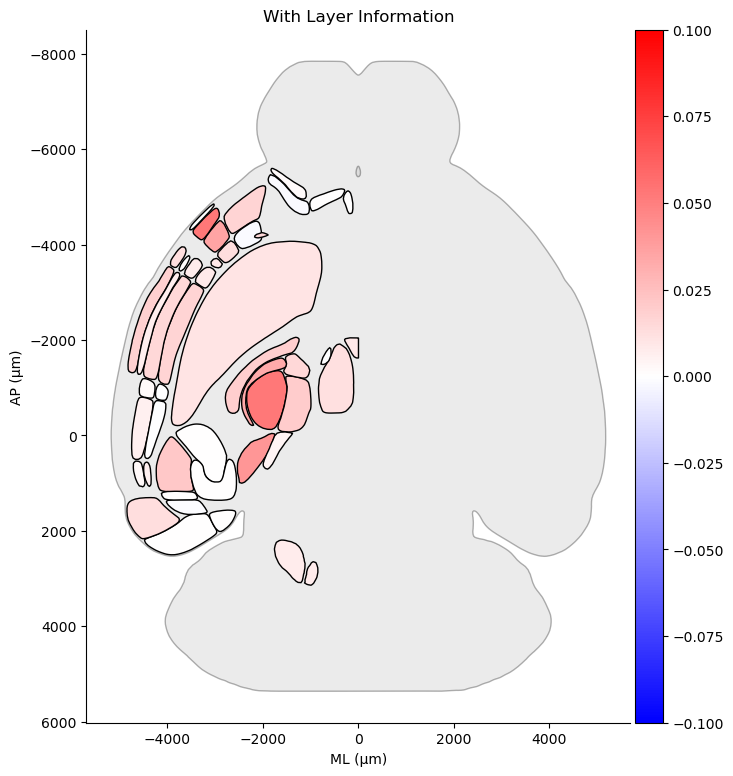

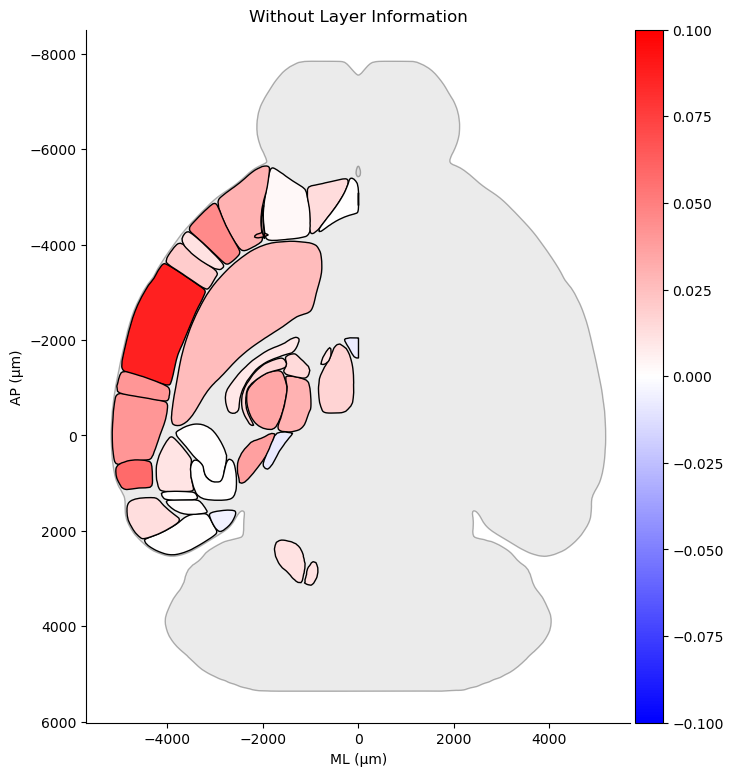

In [15]:
import numpy as np
import pandas as pd
import brainglobe_heatmap as bgh

values1 = mean_dc_1.to_dict()
values2 = mean_dc_2.to_dict()

vmin = -0.1
vmax = 0.1

fig = bgh.Heatmap(
    values=values1,
    hemisphere="left",
    position=4000,
    orientation="horizontal",
    thickness=1500,
    vmin=vmin,
    vmax=vmax,
    cmap="bwr",
    format="2D",
    atlas_name="allen_mouse_25um",
    title="With Layer Information"
).show(xlabel='ML (μm)', ylabel='AP (μm)')

fig = bgh.Heatmap(
    values=values2,
    hemisphere="left",
    position=4000,
    orientation="horizontal",
    thickness=1500,
    vmin=vmin,
    vmax=vmax,
    cmap="bwr",
    format="2D",
    atlas_name="allen_mouse_25um",
    title="Without Layer Information"
).show(xlabel='ML (μm)', ylabel='AP (μm)')

r = 0.466, p = 1.034e-05, MAE = 0.0128


/tmp/ipykernel_262326/1155177421.py:53: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(fontsize=25)


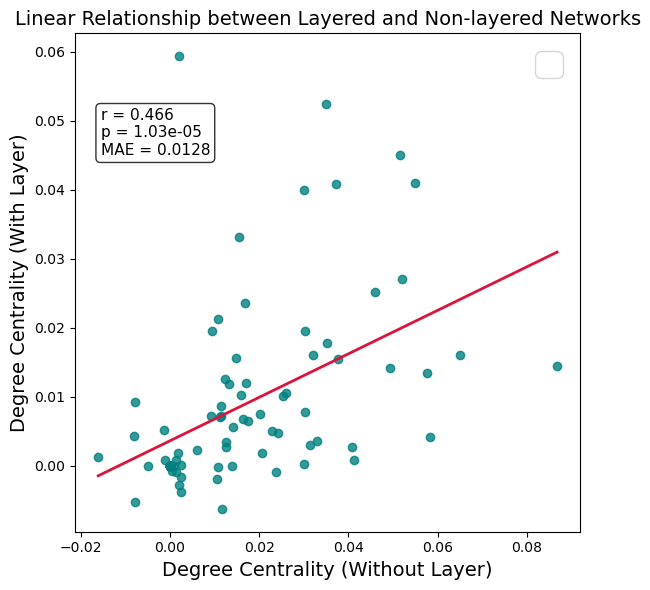

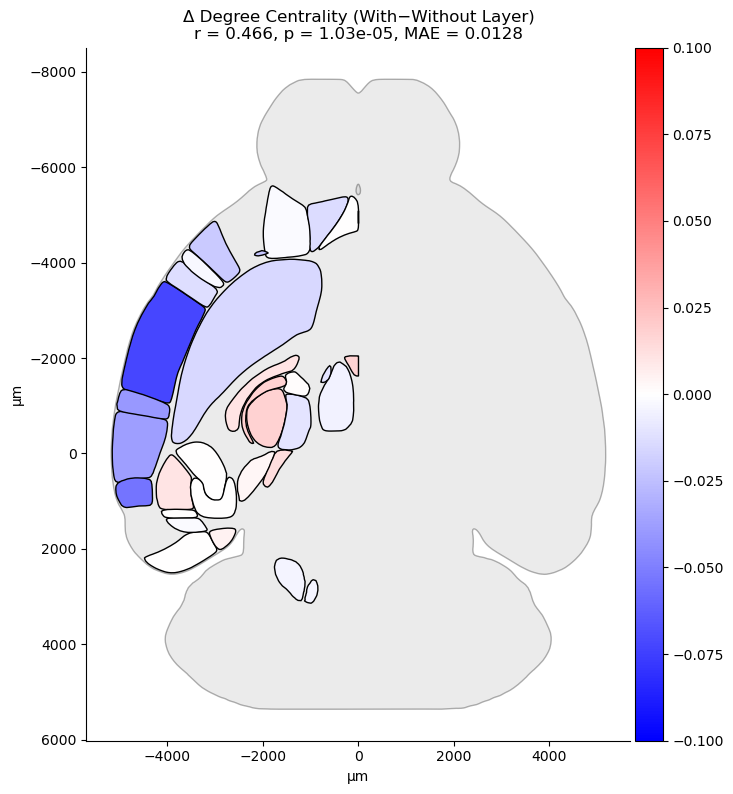

In [16]:
import re
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import pearsonr
import brainglobe_heatmap as bgh
from scipy.stats import linregress

w_layer = mean_dc_1.copy()
wo_layer = mean_dc_2.copy()


def get_base_region(name):
    df = pd.read_csv("./data/region_map.csv", sep="\t")
    region_dict = dict(zip(df.iloc[:,0], df.iloc[:,1]))
    return region_dict.get(name, name)

grouped = {}
for region, val in w_layer.items():
    base = get_base_region(region)
    grouped.setdefault(base, []).append(val)

layer_mean = {base: np.nanmean(vals) for base, vals in grouped.items()}
layer_mean = pd.Series(layer_mean)

common_regions = sorted(set(layer_mean.index) & set(wo_layer.index))
aligned_w = layer_mean[common_regions]
aligned_wo = wo_layer[common_regions]


r, p = pearsonr(aligned_w, aligned_wo)
mae = np.mean(np.abs(aligned_w - aligned_wo))
print(f"r = {r:.3f}, p = {p:.3e}, MAE = {mae:.4f}")

plt.figure(figsize=(6,6))
plt.scatter(aligned_wo, aligned_w, color="teal", alpha=0.8, label="")

slope, intercept, r_val, p_val, stderr = linregress(aligned_wo, aligned_w)

x_fit = np.linspace(aligned_wo.min(), aligned_wo.max(), 100)
y_fit = slope * x_fit + intercept
plt.plot(x_fit, y_fit, color="crimson", linewidth=2, label="")

plt.xlabel("Degree Centrality (Without Layer)", fontsize=14)
plt.ylabel("Degree Centrality (With Layer)", fontsize=14)
plt.title("Linear Relationship between Layered and Non-layered Networks", fontsize=14)

text_str = f"r = {r:.3f}\np = {p:.2e}\nMAE = {mae:.4f}"
plt.text(0.05, 0.85, text_str, transform=plt.gca().transAxes,
         fontsize=11, verticalalignment='top',
         bbox=dict(boxstyle="round", facecolor="white", alpha=0.8))

plt.legend(fontsize=25)
plt.grid(alpha=0)
plt.tight_layout()
plt.savefig("./result/fig/scatter_with_vs_without_layer_stage2.png", dpi=300, bbox_inches="tight")

plt.show()



diff_map = (aligned_w - aligned_wo).to_dict()

fig = bgh.Heatmap(
    values=diff_map,
    hemisphere="left",
    position=4000,
    orientation="horizontal",
    thickness=1500,
    format="2D",
    vmin=-0.1,
    vmax=0.1,
    cmap="bwr",
    atlas_name="allen_mouse_25um",
    title=f"Δ Degree Centrality (With−Without Layer)\n"
          f"r = {r:.3f}, p = {p:.2e}, MAE = {mae:.4f}"
).plot(size=(400,300), axes=False)

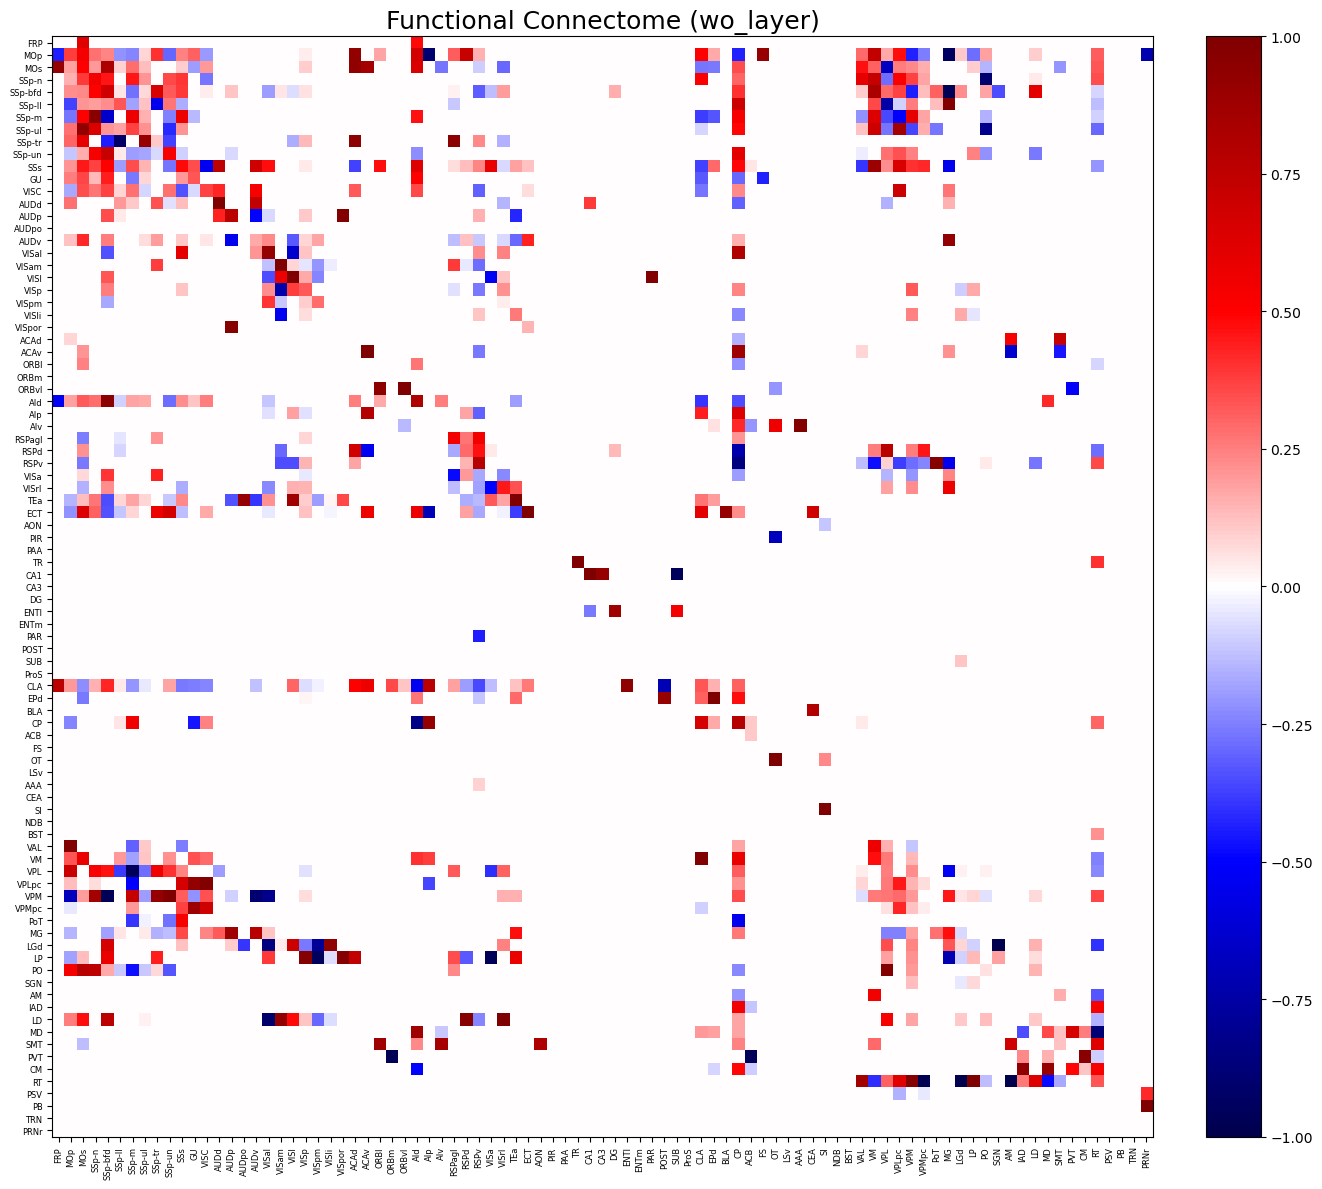

In [17]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import rcParams

rcParams['pdf.fonttype'] = 42
rcParams['ps.fonttype'] = 42

graphs = np.load(graph_path_2)
df = pd.read_csv(label_path_2)
labels = df.iloc[:, 0].astype(str).str.strip().values

adj_matrix = graphs.mean(axis=0)

plt.figure(figsize=(14, 12))

im = plt.imshow(adj_matrix, cmap="seismic", aspect="equal", vmin=-1, vmax=1)

plt.title("Functional Connectome (wo_layer)", fontsize=18)

plt.xticks(ticks=np.arange(len(labels)), labels=labels, rotation=90, fontsize=6)
plt.yticks(ticks=np.arange(len(labels)), labels=labels, fontsize=6)

cbar = plt.colorbar(im, fraction=0.046, pad=0.04)
cbar.ax.tick_params(labelsize=10)

plt.tight_layout()

plt.savefig("./result/fig/functional_connectome_wo_layer_stage2.jpg", format="jpg", dpi=300)
plt.show()


## stage3

In [10]:
import numpy as np
import pandas as pd
import brainglobe_heatmap as bgh
import matplotlib.pyplot as plt

graph_path_1 = './result/w_layer/stage3/tuning/bs64_dp0.3_sw0.7/dynamic_full_graphs.npy'
label_path_1 = './result/w_layer/stage3/df_scaled.csv'

graph_path_2 = './result/wo_layer/stage3/tuning/bs32_dp0.8_sw1.0/dynamic_full_graphs.npy'
label_path_2 = './result/wo_layer/stage3/df_scaled.csv'

def compute_mean_degree_centrality(graph_path, label_path):
    graphs = np.load(graph_path) 
    df = pd.read_csv(label_path)
    labels = df.iloc[:, 0].values 

    degree_centrality = {label: [] for label in labels}

    for t in range(graphs.shape[0]):
        adj = graphs[t]
        degrees = np.sum(adj, axis=1)
        norm_degrees = degrees / (adj.shape[0] - 1)
        for i, region in enumerate(labels):
            degree_centrality[region].append(norm_degrees[i])

    dc_df = pd.DataFrame(degree_centrality)
    mean_dc = dc_df.mean()

    merged = {}
    for name, val in mean_dc.items():
        if '-' in name:
            key = name#.split('-')[0]
            merged.setdefault(key, []).append(val)
        else:
            merged.setdefault(name, []).append(val)
    merged_dc = pd.Series({k: pd.Series(v).mean() for k, v in merged.items()})
    return merged_dc

mean_dc_1 = compute_mean_degree_centrality(graph_path_1, label_path_1)
mean_dc_2 = compute_mean_degree_centrality(graph_path_2, label_path_2)

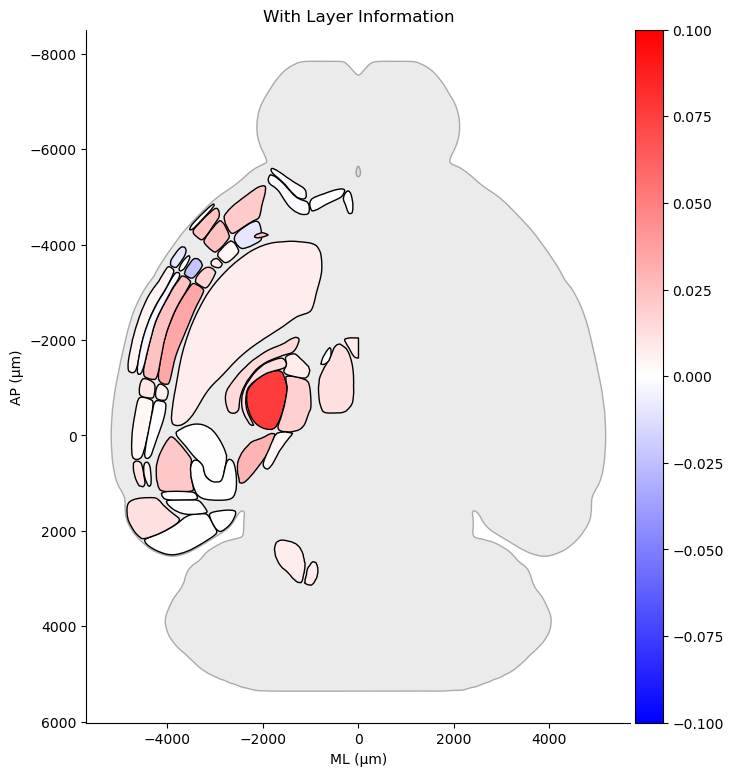

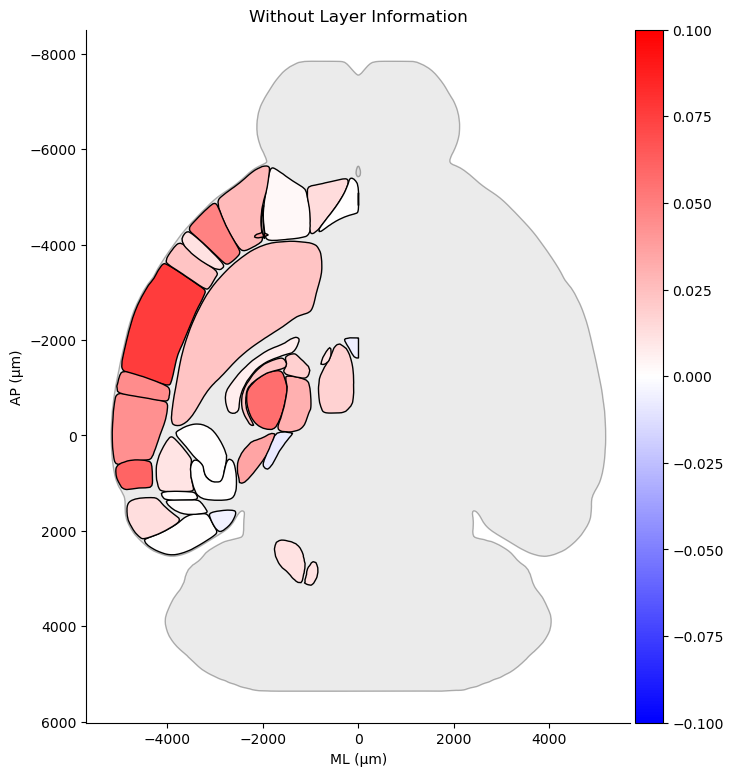

In [2]:
import numpy as np
import pandas as pd
import brainglobe_heatmap as bgh

values1 = mean_dc_1.to_dict()
values2 = mean_dc_2.to_dict()

vmin = -0.1
vmax = 0.1

fig = bgh.Heatmap(
    values=values1,
    hemisphere="left",
    position=4000,
    orientation="horizontal",
    thickness=1500,
    vmin=vmin,
    vmax=vmax,
    cmap="bwr",
    format="2D",
    atlas_name="allen_mouse_25um",
    title="With Layer Information"
).show(xlabel='ML (μm)', ylabel='AP (μm)')

fig = bgh.Heatmap(
    values=values2,
    hemisphere="left",
    position=4000,
    orientation="horizontal",
    thickness=1500,
    vmin=vmin,
    vmax=vmax,
    cmap="bwr",
    format="2D",
    atlas_name="allen_mouse_25um",
    title="Without Layer Information"
).show(xlabel='ML (μm)', ylabel='AP (μm)')


r = 0.486, p = 3.749e-06, MAE = 0.0135


/tmp/ipykernel_270174/1497357260.py:53: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(fontsize=25)


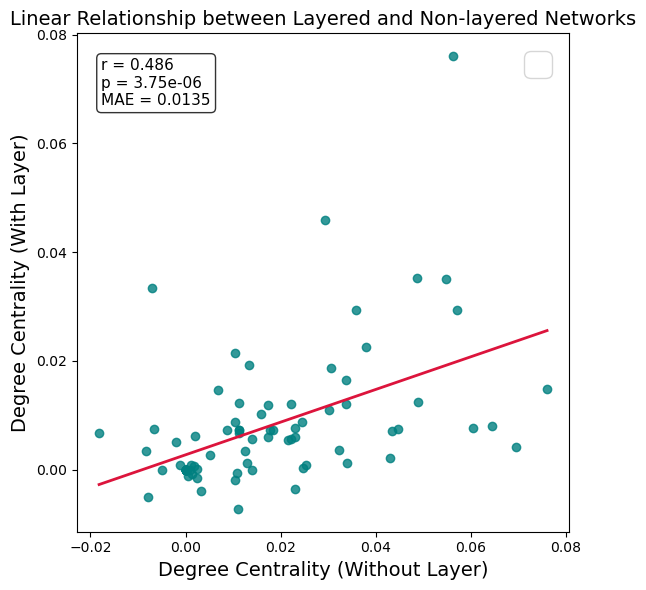

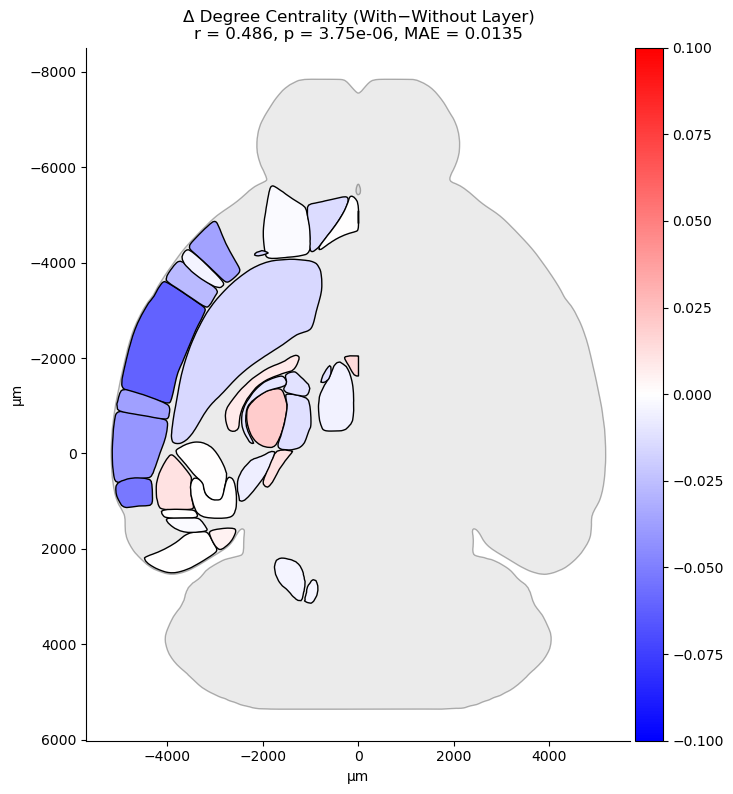

In [3]:
import re
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import pearsonr
import brainglobe_heatmap as bgh
from scipy.stats import linregress

w_layer = mean_dc_1.copy()
wo_layer = mean_dc_2.copy()


def get_base_region(name):
    df = pd.read_csv("./data/region_map.csv", sep="\t")
    region_dict = dict(zip(df.iloc[:,0], df.iloc[:,1]))
    return region_dict.get(name, name)

grouped = {}
for region, val in w_layer.items():
    base = get_base_region(region)
    grouped.setdefault(base, []).append(val)

layer_mean = {base: np.nanmean(vals) for base, vals in grouped.items()}
layer_mean = pd.Series(layer_mean)

common_regions = sorted(set(layer_mean.index) & set(wo_layer.index))
aligned_w = layer_mean[common_regions]
aligned_wo = wo_layer[common_regions]


r, p = pearsonr(aligned_w, aligned_wo)
mae = np.mean(np.abs(aligned_w - aligned_wo))
print(f"r = {r:.3f}, p = {p:.3e}, MAE = {mae:.4f}")

plt.figure(figsize=(6,6))
plt.scatter(aligned_wo, aligned_w, color="teal", alpha=0.8, label="")

slope, intercept, r_val, p_val, stderr = linregress(aligned_wo, aligned_w)

x_fit = np.linspace(aligned_wo.min(), aligned_wo.max(), 100)
y_fit = slope * x_fit + intercept
plt.plot(x_fit, y_fit, color="crimson", linewidth=2, label="")

plt.xlabel("Degree Centrality (Without Layer)", fontsize=14)
plt.ylabel("Degree Centrality (With Layer)", fontsize=14)
plt.title("Linear Relationship between Layered and Non-layered Networks", fontsize=14)

text_str = f"r = {r:.3f}\np = {p:.2e}\nMAE = {mae:.4f}"
plt.text(0.05, 0.95, text_str, transform=plt.gca().transAxes,
         fontsize=11, verticalalignment='top',
         bbox=dict(boxstyle="round", facecolor="white", alpha=0.8))

plt.legend(fontsize=25)
plt.grid(alpha=0)
plt.tight_layout()
plt.savefig("./result/fig/scatter_with_vs_without_layer_stage3.png", dpi=300, bbox_inches="tight")

plt.show()



diff_map = (aligned_w - aligned_wo).to_dict()

fig = bgh.Heatmap(
    values=diff_map,
    hemisphere="left",
    position=4000,
    orientation="horizontal",
    thickness=1500,
    format="2D",
    vmin=-0.1,
    vmax=0.1,
    cmap="bwr",
    atlas_name="allen_mouse_25um",
    title=f"Δ Degree Centrality (With−Without Layer)\n"
          f"r = {r:.3f}, p = {p:.2e}, MAE = {mae:.4f}"
).plot(size=(400,300), axes=False)

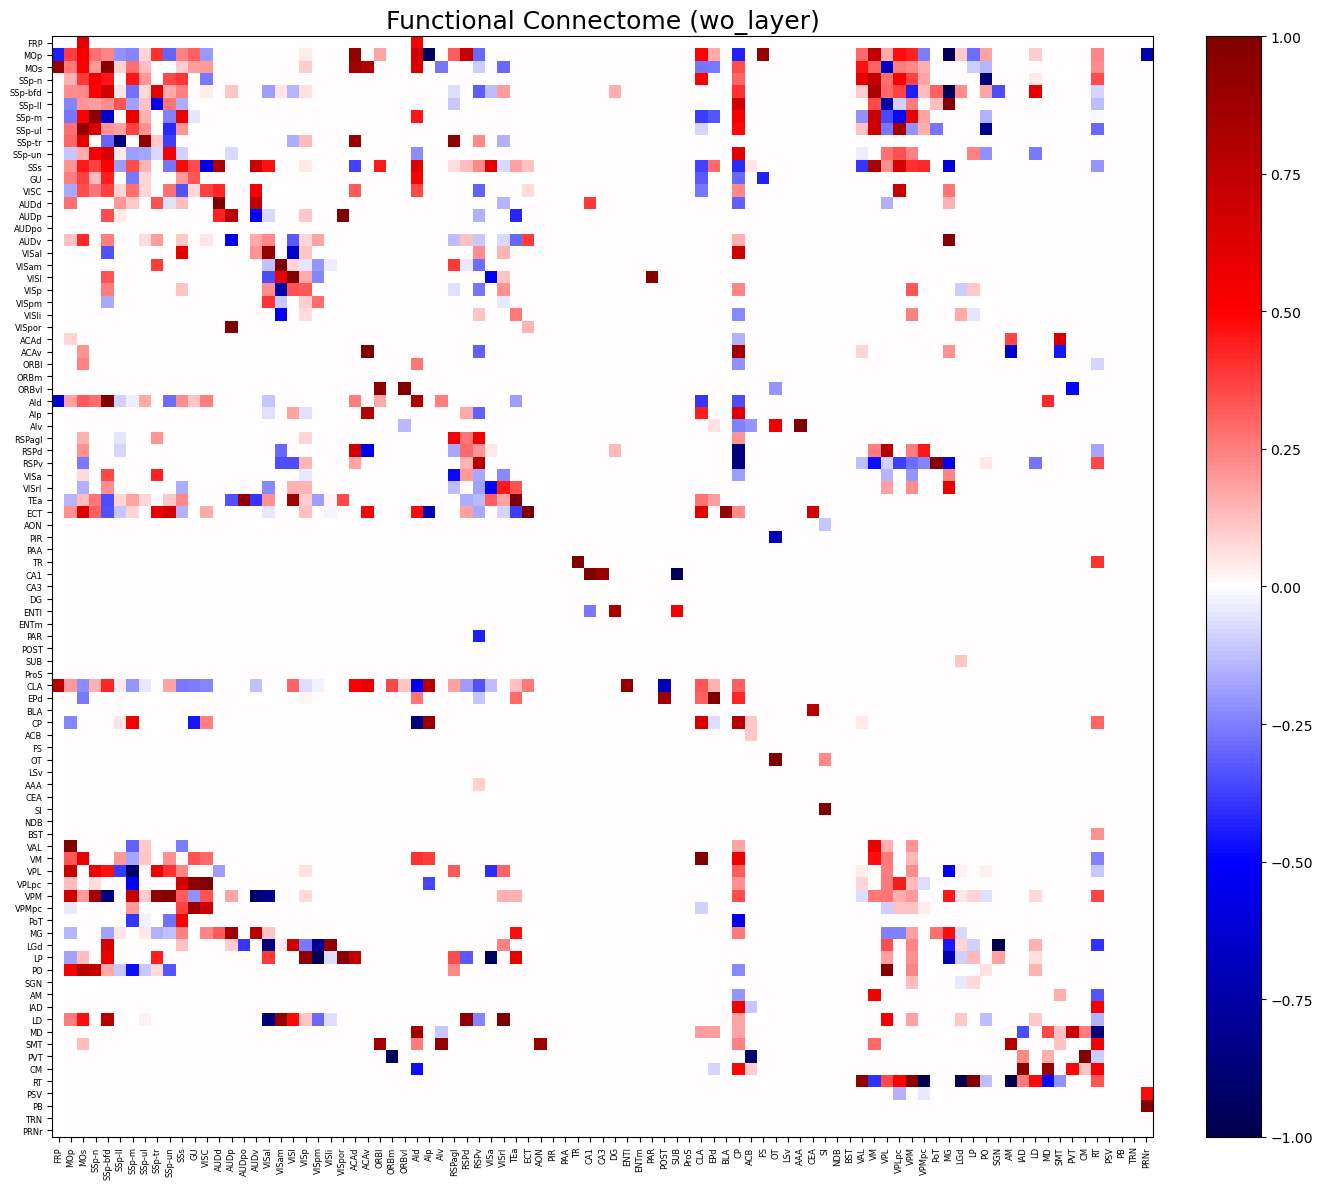

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import rcParams
rcParams['font.family'] = 'DejaVu Sans'
rcParams['pdf.fonttype'] = 42
rcParams['ps.fonttype'] = 42

graphs = np.load(graph_path_2)
df = pd.read_csv(label_path_2)
labels = df.iloc[:, 0].astype(str).str.strip().values

adj_matrix = graphs.mean(axis=0)

plt.figure(figsize=(14, 12))

im = plt.imshow(adj_matrix, cmap="seismic", aspect="equal", vmin=-1, vmax=1)

plt.title("Functional Connectome (wo_layer)", fontsize=18)

plt.xticks(ticks=np.arange(len(labels)), labels=labels, rotation=90, fontsize=6)
plt.yticks(ticks=np.arange(len(labels)), labels=labels, fontsize=6)

cbar = plt.colorbar(im, fraction=0.046, pad=0.04)
cbar.ax.tick_params(labelsize=10)

plt.tight_layout()

plt.savefig("./result/fig/functional_connectome_wo_layer_stage3.jpg", format="jpg", dpi=300)
plt.show()


## Three stages similarity calculation

In [2]:
import numpy as np
import pandas as pd

def load_mean_adj(graph_path, label_path):
    graphs = np.load(graph_path)
    adj = graphs.mean(axis=0)
    df = pd.read_csv(label_path)
    labels = df.iloc[:, 0].astype(str).str.strip().values
    return adj, labels

# paths
stage1_graph_path_2 = './result/wo_layer/stage1/tuning/bs8_dp0.1_sw1.0/dynamic_full_graphs.npy'
stage1_label_path_2 = './result/wo_layer/stage1/df_scaled.csv'

stage2_graph_path_2 = './result/wo_layer/stage2/tuning/bs64_dp0.8_sw1.0/dynamic_full_graphs.npy'
stage2_label_path_2 = './result/wo_layer/stage2/df_scaled.csv'

stage3_graph_path_2 = './result/wo_layer/stage3/tuning/bs32_dp0.8_sw1.0/dynamic_full_graphs.npy'
stage3_label_path_2 = './result/wo_layer/stage3/df_scaled.csv'

A1, L1 = load_mean_adj(stage1_graph_path_2, stage1_label_path_2)
A2, L2 = load_mean_adj(stage2_graph_path_2, stage2_label_path_2)
A3, L3 = load_mean_adj(stage3_graph_path_2, stage3_label_path_2)

# find intersection regions
common = sorted(list(set(L1) & set(L2) & set(L3)))

def reorder(adj, labels, common):
    idx = [np.where(labels == c)[0][0] for c in common]
    return adj[np.ix_(idx, idx)]

A1c = reorder(A1, L1, common)
A2c = reorder(A2, L2, common)
A3c = reorder(A3, L3, common)

def consistency(A, B, eps=0):
    triu = np.triu_indices(A.shape[0], k=1)

    a = A[triu]
    b = B[triu]

    mask = (np.abs(a) > eps) | (np.abs(b) > eps)

    a = a[mask]
    b = b[mask]

    mean_diff = np.abs(a - b).mean()

    return 1 - mean_diff / 2

c12 = consistency(A1c, A2c)
c13 = consistency(A1c, A3c)
c23 = consistency(A2c, A3c)

print("Intersection brain regions:", len(common))
print("Consistency (Stage1 vs Stage2):", round(c12, 4))
print("Consistency (Stage1 vs Stage3):", round(c13, 4))
print("Consistency (Stage2 vs Stage3):", round(c23, 4))

Intersection brain regions: 89
Consistency (Stage1 vs Stage2): 0.9283
Consistency (Stage1 vs Stage3): 0.9246
Consistency (Stage2 vs Stage3): 0.9901


In [3]:
import numpy as np
import pandas as pd


def load_mean_adj(graph_path, label_path):
    graphs = np.load(graph_path)
    adj = graphs.mean(axis=0)
    df = pd.read_csv(label_path)
    labels = df.iloc[:, 0].astype(str).str.strip().values
    return adj, labels


# paths
stage1_graph_path_2 = 'BWM/result/wo_layer/stage1/tuning/bs8_dp0.1_sw1.0/dynamic_full_graphs.npy'
stage1_label_path_2 = 'BWM/result/wo_layer/stage1/df_scaled.csv'

stage2_graph_path_2 = 'BWM/result/wo_layer/stage2/tuning/bs64_dp0.8_sw1.0/dynamic_full_graphs.npy'
stage2_label_path_2 = 'BWM/result/wo_layer/stage2/df_scaled.csv'

stage3_graph_path_2 = 'BWM/result/wo_layer/stage3/tuning/bs32_dp0.8_sw1.0/dynamic_full_graphs.npy'
stage3_label_path_2 = 'BWM/result/wo_layer/stage3/df_scaled.csv'


A1, L1 = load_mean_adj(stage1_graph_path_2, stage1_label_path_2)
A2, L2 = load_mean_adj(stage2_graph_path_2, stage2_label_path_2)
A3, L3 = load_mean_adj(stage3_graph_path_2, stage3_label_path_2)


# find intersection regions
common = sorted(list(set(L1) & set(L2) & set(L3)))


def reorder(adj, labels, common):
    idx = [np.where(labels == c)[0][0] for c in common]
    return adj[np.ix_(idx, idx)]


A1c = reorder(A1, L1, common)
A2c = reorder(A2, L2, common)
A3c = reorder(A3, L3, common)


def edge_mae(A, B, eps=0, mode="all"):
    if A.shape != B.shape:
        raise ValueError("A and B must have the same shape.")

    n = A.shape[0]

    if mode == "offdiag":
        region_mask = ~np.eye(n, dtype=bool)
    elif mode == "diagonal":
        region_mask = np.eye(n, dtype=bool)
    elif mode == "all":
        region_mask = np.ones((n, n), dtype=bool)
    else:
        raise ValueError("mode must be 'offdiag', 'diagonal', or 'all'.")

    valid_mask = region_mask & (
        (np.abs(A) > eps) | (np.abs(B) > eps)
    )

    if valid_mask.sum() == 0:
        return np.nan

    return np.abs(A[valid_mask] - B[valid_mask]).mean()


mae12 = edge_mae(A1c, A2c)
mae13 = edge_mae(A1c, A3c)
mae23 = edge_mae(A2c, A3c)

print("Intersection brain regions:", len(common))
print("Edge MAE (Stage1 vs Stage2):", round(mae12, 4))
print("Edge MAE (Stage1 vs Stage3):", round(mae13, 4))
print("Edge MAE (Stage2 vs Stage3):", round(mae23, 4))

Intersection brain regions: 89
Edge MAE (Stage1 vs Stage2): 0.1357
Edge MAE (Stage1 vs Stage3): 0.1417
Edge MAE (Stage2 vs Stage3): 0.0196


In [4]:
def top5_change_contribution(A, B, eps=0):
    mask = ~np.eye(A.shape[0], dtype=bool)
    mask &= (np.abs(A) > eps) | (np.abs(B) > eps)

    changes = np.abs(A[mask] - B[mask])
    n_top = max(1, int(np.ceil(len(changes) * 0.05)))

    return changes.size, n_top, 100 * np.sort(changes)[-n_top:].sum() / changes.sum()


for name, A, B in [
    ("Stage I vs Stage II", A1c, A2c),
    ("Stage I vs Stage III", A1c, A3c),
    ("Stage II vs Stage III", A2c, A3c)
]:
    n_edges, n_top, contribution = top5_change_contribution(A, B)

    print(
        f"{name}: top 5% edges ({n_top}/{n_edges}) "
        f"contribute {contribution:.2f}% of total change"
    )

Stage I vs Stage II: top 5% edges (43/850) contribute 43.08% of total change
Stage I vs Stage III: top 5% edges (43/850) contribute 41.40% of total change
Stage II vs Stage III: top 5% edges (43/850) contribute 74.97% of total change


In [6]:
import numpy as np
import pandas as pd
import mpmath as mp
from scipy.stats import pearsonr

mp.mp.dps = 5000

# ============================================================
# load learned graphs
# ============================================================
def load_mean_adj(graph_path, label_path):
    graphs = np.load(graph_path)
    adj = graphs.mean(axis=0)

    df = pd.read_csv(label_path)
    labels = df.iloc[:, 0].astype(str).str.strip().values

    return adj, labels


# ============================================================
# reorder matrix
# ============================================================
def reorder(adj, labels, common):
    labels = np.asarray(labels).astype(str)
    idx = [np.where(labels == c)[0][0] for c in common]
    return adj[np.ix_(idx, idx)]


# ============================================================
# high-precision Pearson p-value
# ============================================================
def pearson_p_mpmath(r, n, digits=30):
    r = mp.mpf(str(abs(r)))
    n = mp.mpf(str(n))

    df = n - 2

    # two-sided p-value for Pearson correlation
    # p = I_{1-r^2}(df/2, 1/2)
    x = 1 - r**2
    p = mp.betainc(df / 2, mp.mpf("0.5"), 0, x, regularized=True)

    return mp.nstr(p, digits, min_fixed=0, max_fixed=0)


# ============================================================
# compare matrices
# ============================================================
def compare_matrix(A, B):
    A = np.abs(np.asarray(A, dtype=float))
    B = np.abs(np.asarray(B, dtype=float))

    triu = np.triu_indices(A.shape[0], k=1)

    a = A[triu]
    b = B[triu]

    valid = np.isfinite(a) & np.isfinite(b)
    a = a[valid]
    b = b[valid]

    mae = np.mean(np.abs(a - b))
    rmse = np.sqrt(np.mean((a - b) ** 2))

    pearson_r, _ = pearsonr(a, b)
    pearson_p = pearson_p_mpmath(pearson_r, len(a), digits=3)

    return {
        "MAE": mae,
        "RMSE": rmse,
        "Pearson_r": pearson_r,
        "Pearson_p": pearson_p
    }


# ============================================================
# learned graphs
# ============================================================
stage1_graph_path_2 = './result/wo_layer/stage1/tuning/bs8_dp0.1_sw1.0/dynamic_full_graphs.npy'
stage1_label_path_2 = './result/wo_layer/stage1/df_scaled.csv'

stage2_graph_path_2 = './result/wo_layer/stage2/tuning/bs64_dp0.8_sw1.0/dynamic_full_graphs.npy'
stage2_label_path_2 = './result/wo_layer/stage2/df_scaled.csv'

stage3_graph_path_2 = './result/wo_layer/stage3/tuning/bs32_dp0.8_sw1.0/dynamic_full_graphs.npy'
stage3_label_path_2 = './result/wo_layer/stage3/df_scaled.csv'


# ============================================================
# load learned graphs
# ============================================================
A1, L1 = load_mean_adj(stage1_graph_path_2, stage1_label_path_2)
A2, L2 = load_mean_adj(stage2_graph_path_2, stage2_label_path_2)
A3, L3 = load_mean_adj(stage3_graph_path_2, stage3_label_path_2)


# ============================================================
# load layer matrix
# ============================================================
df_layers = pd.read_excel(
    'SEU_net_wo_corticalLayers.xlsx',
    header=1,
    index_col=1
)

df_layers = df_layers.iloc[:, 1:]

layer_labels = df_layers.index.astype(str).str.strip().values
A_layer = df_layers.values.astype(float)


# ============================================================
# intersection
# ============================================================
common = sorted(list(set(L1) & set(L2) & set(L3) & set(layer_labels)))

print(f"\nIntersection brain regions: {len(common)}")


# ============================================================
# reorder
# ============================================================
A1c = reorder(A1, L1, common)
A2c = reorder(A2, L2, common)
A3c = reorder(A3, L3, common)
Alc = reorder(A_layer, layer_labels, common)


# ============================================================
# compare
# ============================================================
results = {
    "Stage1_vs_Layer": compare_matrix(A1c, Alc),
    "Stage2_vs_Layer": compare_matrix(A2c, Alc),
    "Stage3_vs_Layer": compare_matrix(A3c, Alc),
}

df_results = pd.DataFrame(results).T


# ============================================================
# print only
# ============================================================
df_print = df_results.copy()

df_print["MAE"] = df_print["MAE"].map(lambda x: f"{x:.4f}")
df_print["RMSE"] = df_print["RMSE"].map(lambda x: f"{x:.4f}")
df_print["Pearson_r"] = df_print["Pearson_r"].map(lambda x: f"{x:.4f}")

print("\nComparison results:")
print(df_print)


Intersection brain regions: 89

Comparison results:
                    MAE    RMSE Pearson_r  Pearson_p
Stage1_vs_Layer  0.1265  0.7541    0.6771  8.38e-524
Stage2_vs_Layer  0.1258  0.7517    0.6888  4.16e-549
Stage3_vs_Layer  0.1262  0.7524    0.6865  4.17e-544
